# A14 设备可能出问题时，什么时候值得停机检查？

将故障概率转换为预期维护收益，受最多检查 40 台的容量约束。比较不检查、固定 0.5 阈值与按净收益排序；概率校准与决策收益分别核验。

先修：B09、B29；概率校准、期望损失、排序与容量约束。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 明确维修作用与成本
模拟传感器特征与故障结果；故障标签表示不干预时的潜在故障。检查每台成本 40，故障损失 600，检查可消除 85% 风险。这个干预有效性是教学假设，真实应用需独立证据。

In [2]:
import numpy as np,pandas as pd,json
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss
X,y=make_classification(n_samples=1600,n_features=7,n_informative=5,weights=[0.88,0.12],class_sep=1.3,random_state=114)
X_train,X_hold,y_train,y_hold=train_test_split(X,y,test_size=0.5,stratify=y,random_state=114)
X_val,X_test,y_val,y_test=train_test_split(X_hold,y_hold,test_size=0.5,stratify=y_hold,random_state=114)
inspection_cost,failure_loss,effectiveness,capacity=40,600,0.85,40
raw=make_pipeline(StandardScaler(),LogisticRegression(class_weight='balanced',max_iter=500)).fit(X_train,y_train)
calibrated=CalibratedClassifierCV(make_pipeline(StandardScaler(),LogisticRegression(class_weight='balanced',max_iter=500)),method='sigmoid',cv=3).fit(X_train,y_train)


## 2. 先用验证概率质量选择概率模型
误报和漏报成本不能直接修复概率偏差；先用验证 Brier 分数比较原始与校准概率，锁定候选后再看测试。校准不一定获胜，因此由实际验证结果选择。

In [3]:
candidates={'raw':raw,'calibrated':calibrated}
validation_brier={name:float(brier_score_loss(y_val,estimator.predict_proba(X_val)[:,1])) for name,estimator in candidates.items()}
probability_model=min(validation_brier,key=validation_brier.get)
p=candidates[probability_model].predict_proba(X_test)[:,1]
threshold=inspection_cost/(failure_loss*effectiveness)
benefit=p*failure_loss*effectiveness-inspection_cost


## 3. 正净收益且容量允许才检查
检查收益是可避免故障损失减去检查成本。设备检查耗时相同时，按正净收益从大到小取前 40 台；若检查时长不同应改背包或约束优化，而不能继续简单排序。

In [4]:
def choose_inspections(probability,minimum_threshold,max_checks):
    eligible=np.flatnonzero(probability>=minimum_threshold)
    ordered=eligible[np.argsort(-probability[eligible])]
    mask=np.zeros(len(probability),dtype=bool); mask[ordered[:max_checks]]=True
    return mask
policies={'none':np.zeros(len(p),dtype=bool),'threshold_0_5':choose_inspections(p,0.5,capacity),'net_benefit':choose_inspections(p,threshold,capacity)}
def policy_cost(mask,truth):
    costs=inspection_cost*mask+failure_loss*truth*(1-effectiveness*mask)
    return {'total_cost':float(costs.sum()),'inspections':int(mask.sum()),'uninspected_failures':int(np.sum(truth & ~mask))}
scores={name:policy_cost(mask,y_test.astype(bool)) for name,mask in policies.items()}
assert all(mask.sum()<=capacity for mask in policies.values())


## 4. 决策报告区分预测、假设与实际情景结算
测试标签不参与检查排序。检查后的残余故障成本按 15% 期望值结算，属于模拟干预假设下的评价，不是观察到的真实维修效果。报告被容量挡住的正收益设备。

In [5]:
selected=policies['net_benefit']
queue=pd.DataFrame({'device':np.arange(len(p)),'probability':p,'expected_net_benefit':benefit,'inspect':selected,'simulated_failure_without_action':y_test})
queue.sort_values('expected_net_benefit',ascending=False).to_csv(OUT_DIR/'maintenance_queue.csv',index=False)
metrics={'probability_model':probability_model,'validation_brier':validation_brier,'test_brier':float(brier_score_loss(y_test,p)),'action_threshold':threshold,'capacity':capacity,'costs_under_assumed_effectiveness':scores,'positive_benefit_without_capacity':int(np.sum((benefit>0)&~selected))}
(OUT_DIR/'metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
advice=f'在检查成本 {inspection_cost}、故障损失 {failure_loss}、风险消除比例 {effectiveness:.0%} 的假设下，理论阈值 {threshold:.3f}；容量限定后检查 {int(selected.sum())} 台。测试情景期望结算成本 {scores["net_benefit"]["total_cost"]:.2f}，不检查为 {scores["none"]["total_cost"]:.2f}。概率模型由验证集选择为 {probability_model}。维修效果是外加假设，若效果下降、检查时长不一致或数据变化，应重新建模。'
(OUT_DIR/'决策建议.md').write_text('# 维护建议\n\n'+advice,encoding='utf-8')
pd.DataFrame(scores).T['total_cost'].plot.bar(); plt.ylabel('模拟期望成本'); plt.xticks(rotation=15); plt.tight_layout(); plt.savefig(OUT_DIR/'maintenance_cost.png'); plt.close(); print(metrics)


{'probability_model': 'calibrated', 'validation_brier': {'raw': 0.0803071585982848, 'calibrated': 0.04474469729236851}, 'test_brier': 0.04872725557281508, 'action_threshold': 0.0784313725490196, 'capacity': 40, 'costs_under_assumed_effectiveness': {'none': {'total_cost': 29400.0, 'inspections': 0, 'uninspected_failures': 49}, 'threshold_0_5': {'total_cost': 17030.0, 'inspections': 35, 'uninspected_failures': 22}, 'net_benefit': {'total_cost': 15700.0, 'inspections': 40, 'uninspected_failures': 19}}, 'positive_benefit_without_capacity': 56}


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

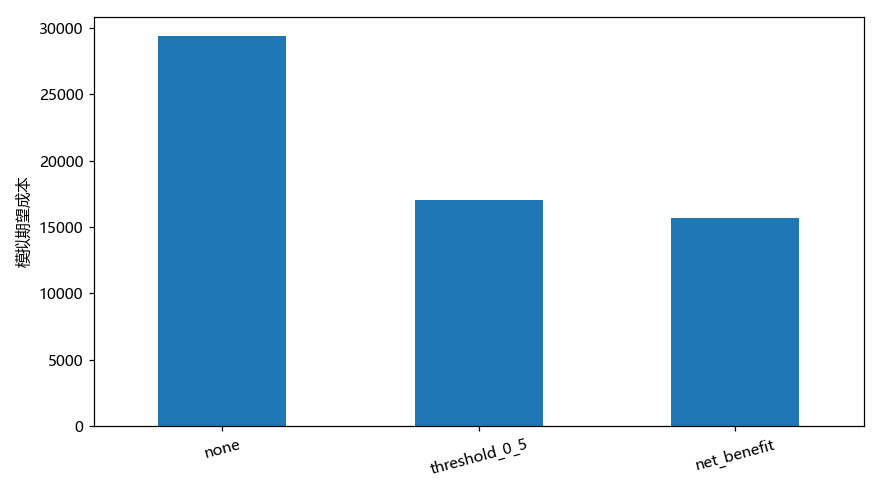

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
有故障风险并不自动意味着检查有效。此处潜在结果与维护效果来自教学模拟，真实观察标签不能直接识别维修因果效果。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。